In [ ]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv('/content/Titanic-Dataset.csv')
df['Age'] = df['Age'].fillna(df['Age'].median())
features = df[['Pclass','Age','SibSp','Parch','Fare']]
print('Original data:\n',features.head())


Original data:
    Pclass   Age  SibSp  Parch     Fare
0       3  22.0      1      0   7.2500
1       1  38.0      1      0  71.2833
2       3  26.0      0      0   7.9250
3       1  35.0      1      0  53.1000
4       3  35.0      0      0   8.0500


In [ ]:
minmax= MinMaxScaler()
normalized = minmax.fit_transform(features)
print('\nNormalized data(first 5 rows):\n', normalized[:5].round(3))
print('\nNormalized range:', normalized.min(), 'to', normalized.max())


Normalized data(first 5 rows):
 [[1.    0.271 0.125 0.    0.014]
 [0.    0.472 0.125 0.    0.139]
 [1.    0.321 0.    0.    0.015]
 [0.    0.435 0.125 0.    0.104]
 [1.    0.435 0.    0.    0.016]]

Normalized range: 0.0 to 1.0


In [ ]:
scaler = StandardScaler()
standardized = scaler.fit_transform(features)
print('\nStandardized data(first 5 rows):\n', standardized[:5].round(3))
print('\nStandardized mean:', standardized.mean().round(4), 'std:', standardized.std().round(4))


Standardized data(first 5 rows):
 [[ 0.827 -0.566  0.433 -0.474 -0.502]
 [-1.566  0.664  0.433 -0.474  0.787]
 [ 0.827 -0.258 -0.475 -0.474 -0.489]
 [-1.566  0.433  0.433 -0.474  0.421]
 [ 0.827  0.433 -0.475 -0.474 -0.486]]

Standardized mean: 0.0 std: 1.0


In [ ]:
pca = PCA(n_components=2)
principal_components = pca.fit_transform(standardized)
print('\nShape before PCA:', standardized.shape, '| Shape after PCA:', principal_components.shape)
print('Explained variance ratio:',pca.explained_variance_ratio_.round(4))
print('\nTotal variance captured by @ components:', round(sum(pca.explained_variance_ratio_) *100,2),'%')


Shape before PCA: (891, 5) | Shape after PCA: (891, 2)
Explained variance ratio: [0.3396 0.3252]

Total variance captured by @ components: 66.48 %


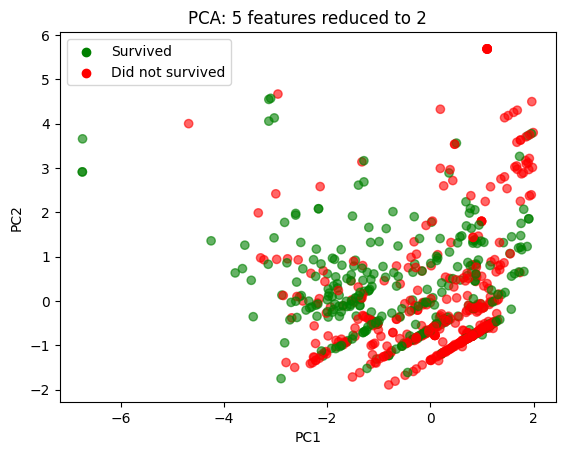

In [ ]:
colors = df['Survived'].map({1: 'green', 0: 'red'})
plt.scatter(principal_components[:, 0], principal_components[:, 1], c=colors, alpha=0.6)
plt.scatter([], [], c='green', label='Survived')
plt.scatter([], [], c='red', label='Did not survived')
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.title('PCA: 5 features reduced to 2')
plt.legend()
plt.show()